# A one-layer transformer learns addition mod N

This notebook walks through what the code in this repository does and why.
The repo builds a tiny transformer from raw weight matrices, with no `nn.Linear`,
no `nn.MultiheadAttention`, and no layer norm, so that every tensor in the model
is something you can print and inspect. It then trains the model on equations

$$a + b \equiv c \pmod N$$

and asks a question that drives much of modern machine-learning research:
**does the model memorize the training examples, or does it learn the rule?**

The tour follows the files in the order data flows through them:

1. `config.py`: the hyperparameters that define the task and the model size
2. `tokenizer.py`: integers become one-hot vectors
3. `data.py`: every equation mod N, shuffled, and split into training and held-out sets
4. `forward.py`: the forward pass, one activation at a time
5. `loss.py`: cross-entropy on the answer token
6. `model.py`: the parameters, the optimizer, and one training step
7. Training runs, plots, and a look inside the trained network

Run the cells in order. Everything runs on CPU; the two training runs take five to ten minutes in total.

In [1]:
import math, importlib
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import SVG, display

import config, tokenizer, data, forward, loss
import model as model_module

torch.manual_seed(0)
torch.set_printoptions(precision=3, sci_mode=False, linewidth=120)

# Colors used throughout: blue for the training set, orange for held-out data.
TRAIN_COLOR, HELDOUT_COLOR = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})

## 1. The task and the model size (`config.py`)

`config.py` is a plain module of global constants. Everything else imports from it.
`modulus` is the N in "mod N". The vocabulary has N number tokens plus one extra
token, with ID N, that stands for the unknown answer. The site calls it `?`.

In [2]:
print(f"modulus (N)      = {config.modulus}")
print(f"d_vocab          = {config.d_vocab}   (N numbers + the '?' token)")
print(f"d_context        = {config.d_context}   tokens per example: (a, b, ?)")
print(f"d_model          = {config.d_model}   width of the residual stream")
print(f"num_heads        = {config.num_heads},  d_head = {config.d_head}")
print(f"d_mlp            = {config.d_mlp}")
print(f"LR = {config.LR},  WEIGHT_DECAY = {config.WEIGHT_DECAY}  (AdamW)")

modulus (N)      = 7
d_vocab          = 8   (N numbers + the '?' token)
d_context        = 3   tokens per example: (a, b, ?)
d_model          = 128   width of the residual stream
num_heads        = 4,  d_head = 32
d_mlp            = 512
LR = 0.001,  WEIGHT_DECAY = 1.0  (AdamW)


## 2. Tokens become one-hot vectors (`tokenizer.py`)

A transformer cannot consume the integer 3 directly. The tokenizer turns each token ID
into a one-hot vector of length `d_vocab`. The string `"3 5"` means the equation
$3 + 5 = ?$, so it encodes to three one-hot rows: token 3, token 5, and the `?` token.

In [3]:
x = tokenizer.tokenize_string("3 5")
print("shape:", tuple(x.shape), "  (d_context, d_vocab)")
print(x)
print("decoded back to IDs:", x.argmax(dim=-1).tolist(), "  <- the last ID is N, the '?' token")

shape: (3, 8)   (d_context, d_vocab)
tensor([[0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1.]])
decoded back to IDs: [3, 5, 7]   <- the last ID is N, the '?' token


## 3. Every equation, shuffled and split (`data.py`)

There are exactly $N^2$ ordered pairs $(a, b)$. `generate_data(n)` draws `n` of them without
replacement, in random order. Inputs replace the answer with `?`; targets hold the true answer.
`generate_data_tensor` does the same and one-hot encodes both.

The whole dataset fits in a grid. Below is the answer $c = (a + b) \bmod N$ for every pair.
The wrap-around diagonals are the structure the model would need to discover to generalize.

first five examples (a, b, ?)  ->  (a, b, c):
    [1, 4, 7] -> [1, 4, 5]
    [2, 2, 7] -> [2, 2, 4]
    [6, 1, 7] -> [6, 1, 0]
    [1, 6, 7] -> [1, 6, 0]
    [6, 5, 7] -> [6, 5, 4]


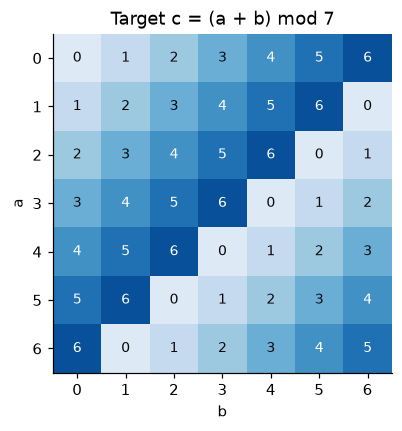

In [4]:
inputs, targets = data.generate_data(config.modulus**2)
print("first five examples (a, b, ?)  ->  (a, b, c):")
for i in range(5):
    print("   ", inputs[i].tolist(), "->", targets[i].tolist())

N = config.modulus
grid = (torch.arange(N)[:, None] + torch.arange(N)[None, :]) % N
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.imshow(grid, cmap="Blues", vmin=-1, vmax=N)
for a in range(N):
    for b in range(N):
        ax.text(b, a, int(grid[a, b]), ha="center", va="center",
                color="white" if grid[a, b] > N / 2 else "#0b0b0b", fontsize=9)
ax.set(xlabel="b", ylabel="a", title=f"Target c = (a + b) mod {N}", xticks=range(N), yticks=range(N))
ax.grid(False)
plt.show()

### The training protocol

The site's Task 9 asks for a fixed shuffle, about 80% of pairs for training, and the rest held out.
The model takes optimizer steps only on the training set. The held-out set is the test of whether
it learned a rule that works for pairs it never saw.

In [5]:
def make_split(N, train_frac=0.8, seed=0):
    torch.manual_seed(seed)
    X, Y = data.generate_data_tensor(N**2)
    n_train = round(train_frac * len(X))
    return (X[:n_train], Y[:n_train]), (X[n_train:], Y[n_train:])

(Xtr, Ytr), (Xho, Yho) = make_split(config.modulus)
print(f"training pairs: {len(Xtr)}   held-out pairs: {len(Xho)}   tensor shape: {tuple(Xtr.shape)}")

training pairs: 39   held-out pairs: 10   tensor shape: (39, 3, 8)


## 4. The forward pass, one activation at a time (`forward.py`)

Here is the architecture diagram from the course site. Read it top to bottom; the code in
`forward_pass` follows the same order.

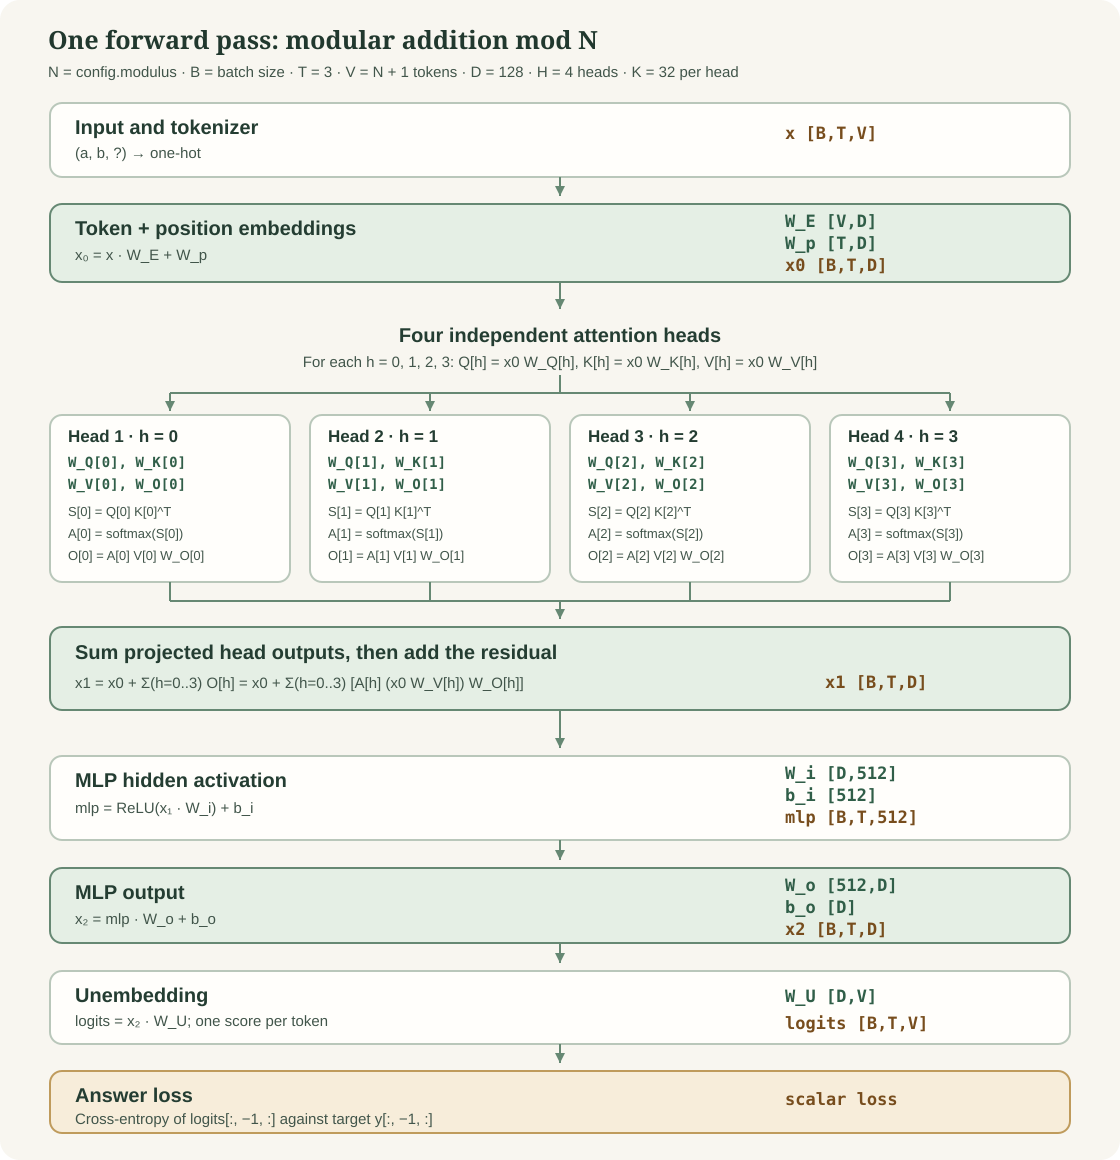

In [6]:
display(SVG("site/architecture.svg"))

`model.py` creates the learnable weights as bare `nn.Parameter` tensors. Each attention weight
holds all four heads at once: `W_Q[h]` is head `h`'s query matrix. `forward_pass` then does, in order:

| activation | expression | shape (per example) | meaning |
|---|---|---|---|
| `x0` | `x @ W_E + W_p` | `(3, d_model)` | token embedding plus position embedding, the residual stream |
| `S` | `x0 W_Q W_Kᵀ x0ᵀ` per head | `(heads, 3, 3)` | attention scores: how much each position wants to look at each other position |
| `A` | `softmax(S)` | `(heads, 3, 3)` | attention weights, rows sum to 1 |
| `x1` | `Σ_heads A x0 W_V W_O + x0` | `(3, d_model)` | heads' outputs added back to the residual stream |
| `mlp` | `relu(x1 W_i) + b_i` | `(3, d_mlp)` | the MLP hidden layer |
| `x2` | `mlp W_o + b_o` | `(3, d_model)` | MLP output |
| `logits` | `x2 @ W_U` | `(3, d_vocab)` | a score for every token at every position |

This is deliberately a teaching model: no causal mask, no $1/\sqrt{d_{head}}$ scaling of the
scores, and no layer normalization. The cell below runs these steps by hand on one batch and
prints the shape of every intermediate tensor, so you can match each line of `forward.py`
to the table.

In [7]:
net = model_module.model()
n_params = sum(p.numel() for p in net.parameters())
print(f"parameters: {n_params:,}")
for name, p in net.named_parameters():
    print(f"   {name:4s} {str(tuple(p.shape)):>18s}")

# The same steps as forward.forward_pass, with shapes printed.
x = Xtr[:4]                                             # a batch of 4 examples
with torch.no_grad():
    x0 = x @ net.W_E + net.W_p
    S = x0.unsqueeze(-3) @ net.W_Q.unsqueeze(-4) @ net.W_K.unsqueeze(-4).mT @ x0.unsqueeze(-3).mT
    A = (S - S.max(dim=-1, keepdim=True).values).softmax(dim=-1)
    x1 = (A @ x0.unsqueeze(-3) @ net.W_V @ net.W_O).sum(dim=-3) + x0
    mlp = torch.relu(x1 @ net.W_i) + net.b_i
    x2 = mlp @ net.W_o + net.b_o
    logits = x2 @ net.W_U
print()
for name, t in [("x (input)", x), ("x0", x0), ("S", S), ("A", A), ("x1", x1), ("mlp", mlp), ("x2", x2), ("logits", logits)]:
    print(f"   {name:10s} {tuple(t.shape)}")
print("\nmatches forward_pass:", torch.allclose(logits, net(x)))
print("attention rows sum to 1:", torch.allclose(A.sum(-1), torch.ones_like(A.sum(-1))))

parameters: 199,680
   W_E            (8, 128)
   W_p            (3, 128)
   W_Q        (4, 128, 32)
   W_K        (4, 128, 32)
   W_V        (4, 128, 32)
   W_O        (4, 32, 128)
   W_i          (128, 512)
   b_i              (512,)
   W_o          (512, 128)
   b_o              (128,)
   W_U            (128, 8)

   x (input)  (4, 3, 8)
   x0         (4, 3, 128)
   S          (4, 4, 3, 3)
   A          (4, 4, 3, 3)
   x1         (4, 3, 128)
   mlp        (4, 3, 512)
   x2         (4, 3, 128)
   logits     (4, 3, 8)

matches forward_pass: True
attention rows sum to 1: True


## 5. Scoring the answer (`loss.py`)

The model outputs `d_vocab` logits at each position. `log_softmax` turns the logits at one
position into log-probabilities, and cross-entropy is the negative log-probability the model
assigned to the correct token. If the model spread its probability evenly over the
vocabulary, the loss would be exactly $\ln(d_{vocab})$. The random initialization is not quite that
even (the biases `b_i` and `b_o` are drawn with standard deviation 1), so the starting loss is a bit
higher than that benchmark, and accuracy is at chance.

### Read the loss carefully

The docstring says the loss should score **the answer position only**. Look at the slice in
`loss.py`: `[:, ...]` selects everything, so the current function averages over all three
positions. That is why `tests/test_loss.py::test_loss_uses_last_token_only` fails on this
checkout. Changing the slice to `[:, -1]` makes the test pass. That is left alone here so the
class code stays as cloned, and this notebook defines its own `answer_loss` for reporting.

Training still works with the all-positions loss. The first two positions just ask the model to
echo back `a` and `b`, which is easy. But it does change the numbers you see, so keep it in mind.

In [8]:
def answer_loss(y, z):
    "Cross-entropy at the final (answer) position only."
    return -(y * z.log_softmax(dim=-1)).sum(dim=-1)[:, -1].mean()

def answer_accuracy(net, X, Y):
    with torch.no_grad():
        return (net(X)[:, -1].argmax(-1) == Y[:, -1].argmax(-1)).float().mean().item()

with torch.no_grad():
    z = net(Xtr)
print(f"repo loss_fn (all positions) : {loss.loss_fn(Ytr, z).item():.3f}")
print(f"answer-only loss             : {answer_loss(Ytr, z).item():.3f}")
print(f"ln(d_vocab) = ln({config.d_vocab})           : {math.log(config.d_vocab):.3f}")
print(f"answer accuracy before training: {answer_accuracy(net, Xtr, Ytr):.2f}  (chance is {1/config.modulus:.2f})")

repo loss_fn (all positions) : 3.343
answer-only loss             : 2.919
ln(d_vocab) = ln(8)           : 2.079
answer accuracy before training: 0.03  (chance is 0.14)


## 6. One training step (`model.py`)

`model.train(inputs, targets)` is this project's name for one optimizer step: zero the gradients,
run the forward pass, compute the loss, backpropagate, and let AdamW update every parameter.
With `dry_run=True` the gradients are computed but the weights are not changed.

AdamW differs from plain SGD in two ways the site points out: it keeps running averages of each
parameter's gradient and squared gradient, so every parameter gets its own step size, and it
applies weight decay as a separate shrink of the weights rather than folding it into the gradient.
Weight decay is set to 1.0 here, which is unusually strong. Keep that in mind for later.

In [9]:
net = model_module.model()
loss_before = net.train(Xtr, Ytr, dry_run=True).item()
print(f"dry run: loss {loss_before:.3f}, gradient on W_E has shape {tuple(net.W_E.grad.shape)}, weights unchanged")
W_E_before = net.W_E.detach().clone()
for step in range(5):
    l = net.train(Xtr, Ytr).item()
    print(f"step {step}: loss {l:.3f}")
print("W_E changed by", (net.W_E.detach() - W_E_before).abs().mean().item(), "on average per entry")

dry run: loss 4.397, gradient on W_E has shape (8, 128), weights unchanged
step 0: loss 4.397
step 1: loss 2.272
step 2: loss 2.397
step 3: loss 2.341
step 4: loss 1.969
W_E changed by 0.003094110172241926 on average per entry


## 7. Training on all of mod 7

Now the full experiment. At step 0 and after every optimizer step, record the answer-only loss and
the answer accuracy on both the training and the held-out set.

**Write down your prediction first.** Do you expect training and held-out loss to fall together?
What would it mean if the training loss went to zero while the held-out loss rose?

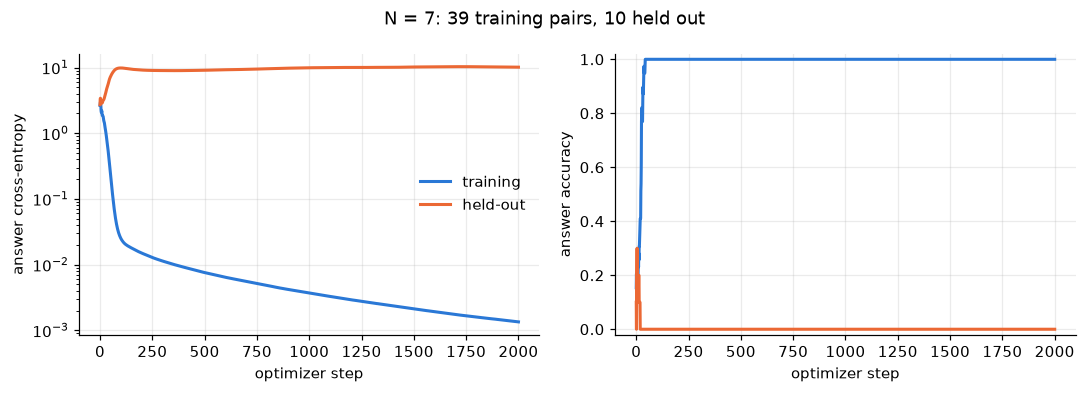

final  train loss 0.0013  held-out loss 10.12
final  train acc  1.00    held-out acc  0.00


In [10]:
def run_experiment(N, steps, train_frac=0.8, seed=0, log_every=1):
    "Train a fresh model on N**2 * train_frac pairs; return the model, data split, and metric history."
    Model = set_modulus(N)
    (Xtr, Ytr), (Xho, Yho) = make_split(N, train_frac, seed)
    torch.manual_seed(seed)
    net = Model()
    hist = {k: [] for k in ["step", "train_loss", "ho_loss", "train_acc", "ho_acc"]}
    for step in range(steps + 1):
        if step % log_every == 0 or step == steps:
            with torch.no_grad():
                hist["step"].append(step)
                hist["train_loss"].append(answer_loss(Ytr, net(Xtr)).item())
                hist["ho_loss"].append(answer_loss(Yho, net(Xho)).item())
                hist["train_acc"].append(answer_accuracy(net, Xtr, Ytr))
                hist["ho_acc"].append(answer_accuracy(net, Xho, Yho))
        if step < steps:
            net.train(Xtr, Ytr)
    return net, (Xtr, Ytr, Xho, Yho), hist

def set_modulus(N):
    "config.py holds module globals, so changing N means reloading the modules that read it."
    config.modulus, config.d_vocab = N, N + 1
    for m in (tokenizer, data, forward, loss, model_module):
        importlib.reload(m)
    return model_module.model

def plot_history(hist, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, key, ylabel in [(ax1, "loss", "answer cross-entropy"), (ax2, "acc", "answer accuracy")]:
        ax.plot(hist["step"], hist[f"train_{key}"], color=TRAIN_COLOR, lw=2, label="training")
        ax.plot(hist["step"], hist[f"ho_{key}"], color=HELDOUT_COLOR, lw=2, label="held-out")
        ax.set(xlabel="optimizer step", ylabel=ylabel)
    ax1.set_yscale("log"); ax2.set_ylim(-0.02, 1.02)
    ax1.legend(loc="center right"); fig.suptitle(title); fig.tight_layout()
    plt.show()

net7, (Xtr, Ytr, Xho, Yho), hist7 = run_experiment(N=7, steps=2000)
plot_history(hist7, "N = 7: 39 training pairs, 10 held out")
print(f"final  train loss {hist7['train_loss'][-1]:.4f}  held-out loss {hist7['ho_loss'][-1]:.2f}")
print(f"final  train acc  {hist7['train_acc'][-1]:.2f}    held-out acc  {hist7['ho_acc'][-1]:.2f}")

### What happened

The training loss collapses toward zero within a couple of hundred steps and training accuracy hits
100%. The held-out loss goes the *other* way: it climbs, and held-out accuracy sits at or near chance.
The model memorized 39 specific equations. It did not learn addition.

This is the gap the course asks you to explain. With N = 7 there are only 49 equations in the world,
and seeing 39 of them is not enough for a 128-dimensional model with about 200,000 parameters to prefer the
general rule over a lookup table. The held-out set is also tiny, so a single prediction flipping moves
its accuracy by 10 percentage points.

### Which equations does it get right?

An N × N grid shows every pair. Held-out cells have a thick border.

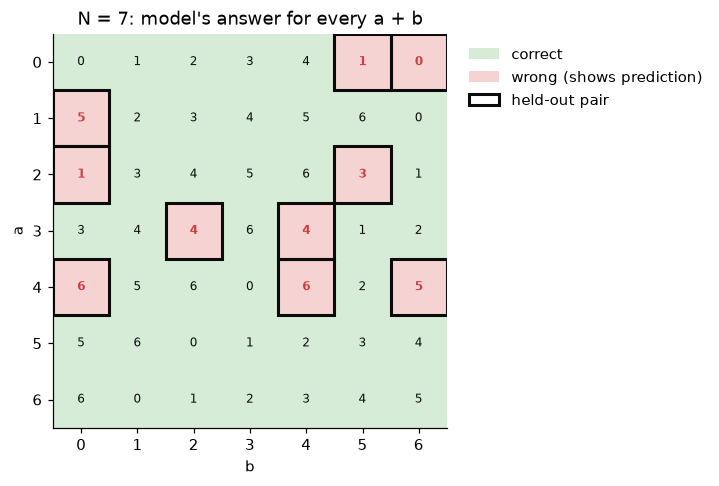

In [11]:
def plot_prediction_grid(net, N, Xho, title):
    all_in, all_out = data.generate_data(N**2)
    a, b, c = all_out[:, 0], all_out[:, 1], all_out[:, 2]
    with torch.no_grad():
        pred = net(tokenizer.tokenize_tensor(all_in))[:, -1].argmax(-1)
    correct = torch.zeros(N, N, dtype=torch.bool); predicted = torch.zeros(N, N, dtype=torch.long)
    correct[a, b] = pred == c; predicted[a, b] = pred
    ho_ab = set(map(tuple, Xho[:, :2].argmax(-1).tolist()))

    cell = min(0.55, 9.5 / N)
    fig, ax = plt.subplots(figsize=(cell * N + 1.2, cell * N + 0.8))
    ax.imshow(correct, cmap=plt.matplotlib.colors.ListedColormap(["#f6d3d3", "#d6ecd6"]), vmin=0, vmax=1)
    for i in range(N):
        for j in range(N):
            ax.text(j, i, int(predicted[i, j]), ha="center", va="center", fontsize=8 if N <= 13 else 6,
                    color="#0b0b0b" if correct[i, j] else "#d03b3b", fontweight="normal" if correct[i, j] else "bold")
            if (i, j) in ho_ab:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, lw=2, ec="#0b0b0b"))
    ax.set(xlabel="b", ylabel="a", title=title, xticks=range(N), yticks=range(N)); ax.grid(False)
    ax.legend(handles=[Patch(fc="#d6ecd6", label="correct"), Patch(fc="#f6d3d3", label="wrong (shows prediction)"),
                       Patch(fc="white", ec="#0b0b0b", lw=2, label="held-out pair")],
              loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.show()
    return correct

_ = plot_prediction_grid(net7, 7, Xho, "N = 7: model's answer for every a + b")

## 8. Looking inside: what does the `?` token attend to?

The answer is produced at the third position, so the question is what that position reads from the
rest of the sequence. `A[h, 2, :]` is head `h`'s attention from the `?` position to positions
(a, b, ?). Averaging over every input shows each head's habit.

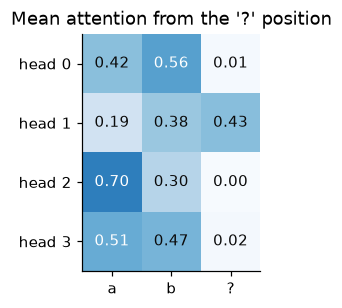

In [12]:
def attention_from_answer(net, X):
    with torch.no_grad():
        x0 = X @ net.W_E + net.W_p
        S = x0.unsqueeze(-3) @ net.W_Q.unsqueeze(-4) @ net.W_K.unsqueeze(-4).mT @ x0.unsqueeze(-3).mT
        A = (S - S.max(dim=-1, keepdim=True).values).softmax(dim=-1)
    return A[:, :, -1, :]        # (batch, heads, 3): attention from '?' to each position

A_ans = attention_from_answer(net7, torch.cat([Xtr, Xho])).mean(0)   # (heads, 3)
fig, ax = plt.subplots(figsize=(4.2, 2.8))
ax.imshow(A_ans, cmap="Blues", vmin=0, vmax=1)
for h in range(A_ans.shape[0]):
    for p in range(3):
        ax.text(p, h, f"{A_ans[h, p]:.2f}", ha="center", va="center", color="white" if A_ans[h, p] > 0.5 else "#0b0b0b")
ax.set(xticks=range(3), xticklabels=["a", "b", "?"], yticks=range(A_ans.shape[0]),
       yticklabels=[f"head {h}" for h in range(A_ans.shape[0])], title="Mean attention from the '?' position")
ax.grid(False); plt.show()

Different heads split the work: some look mostly at `a`, some at `b`, some spread out. Because the
heads' outputs are summed into the residual stream, the MLP then sees a mix of information about both
operands and has to turn it into the answer.

Another view is the output distribution for a single equation before and after training.

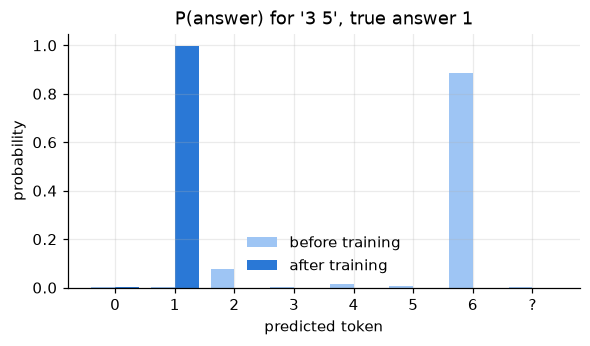

In [13]:
eq = "3 5"
untrained = set_modulus(7)()
with torch.no_grad():
    p_before = untrained(tokenizer.tokenize_string(eq).unsqueeze(0))[0, -1].softmax(-1)
    p_after = net7(tokenizer.tokenize_string(eq).unsqueeze(0))[0, -1].softmax(-1)
labels = [str(i) for i in range(7)] + ["?"]
fig, ax = plt.subplots(figsize=(6, 3))
w = 0.4
ax.bar([i - w/2 for i in range(8)], p_before, w, color="#9ec5f4", label="before training")
ax.bar([i + w/2 for i in range(8)], p_after, w, color=TRAIN_COLOR, label="after training")
ax.set(xticks=range(8), xticklabels=labels, ylabel="probability", xlabel="predicted token",
       title=f"P(answer) for '{eq}', true answer {(3 + 5) % 7}")
ax.legend(); plt.show()

## 9. Experiment 2: a larger N

The site suggests changing exactly one thing and comparing against the baseline. The natural
question after the N = 7 result is whether more data helps. With N = 23 there are 529 equations,
and the model trains on 423 of them. The helper reloads the modules so `config.modulus` changes
cleanly; nothing else about the model or optimizer changes.

Before running it, predict: will the held-out curve look like N = 7, or different?

This run logs every 10 steps and takes about five minutes on CPU.

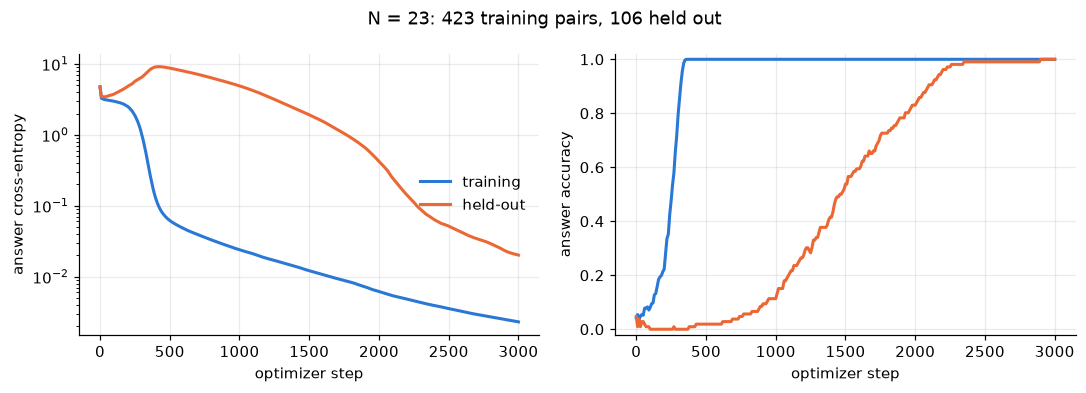

final  train acc  1.00    held-out acc  1.00
training accuracy first reached 100% at step 360
held-out accuracy first reached 100% at step 2900


In [14]:
net23, (Xtr23, Ytr23, Xho23, Yho23), hist23 = run_experiment(N=23, steps=3000, log_every=10)
plot_history(hist23, "N = 23: 423 training pairs, 106 held out")
first_perfect = next((s for s, a in zip(hist23["step"], hist23["ho_acc"]) if a == 1.0), None)
print(f"final  train acc  {hist23['train_acc'][-1]:.2f}    held-out acc  {hist23['ho_acc'][-1]:.2f}")
print(f"training accuracy first reached 100% at step {next(s for s, a in zip(hist23['step'], hist23['train_acc']) if a == 1.0)}")
print(f"held-out accuracy first reached 100% at step {first_perfect}")

### Memorize first, generalize later

The same model that failed completely at N = 7 solves N = 23 for every held-out pair.
Look at the *order* of events in the curves. Training accuracy reaches 100% first, within a few
hundred steps, while held-out loss is still rising: the model has memorized its 423 examples.
Then, hundreds of steps later, the held-out loss turns around and falls, and held-out accuracy
climbs from near chance to 100%.

This delayed generalization is called **grokking** (Power et al., 2022), and modular addition is
the task it was first described on. The usual explanation is a competition between two solutions.
The memorizing solution is quick to find but needs large, specific weights. The general solution,
which implements addition with periodic features in the embeddings, is harder to find but can be
written with smaller weights. Weight decay, set to a strong 1.0 in `config.py`, keeps shrinking the
weights, which penalizes the lookup table and slowly favors the rule. With only 39 training pairs at
N = 7, there is too little data to pin down the rule, so the lookup table wins.

Try N = 13 as an intermediate case. In a run with the same seed it still had not generalized after
8,000 steps, though held-out accuracy had started to creep upward. Where would you look to decide
whether it was about to grok?

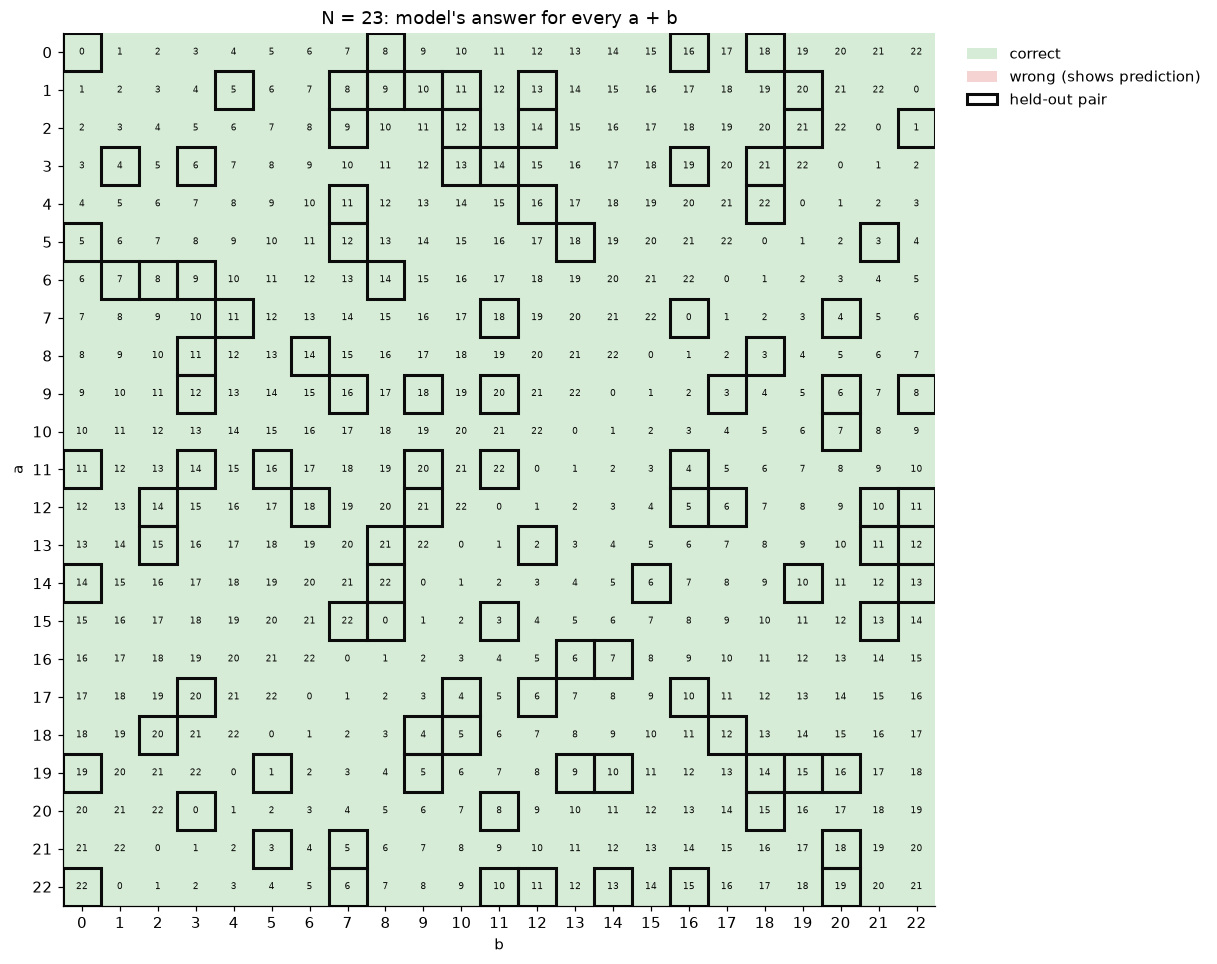

In [15]:
_ = plot_prediction_grid(net23, 23, Xho23, "N = 23: model's answer for every a + b")

The attention pattern of the generalizing model, for comparison with the memorizing N = 7 one:

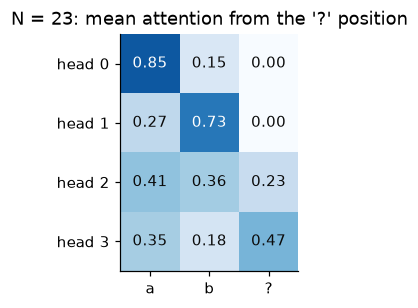

In [16]:
A_ans = attention_from_answer(net23, torch.cat([Xtr23, Xho23])).mean(0)
fig, ax = plt.subplots(figsize=(4.2, 2.8))
ax.imshow(A_ans, cmap="Blues", vmin=0, vmax=1)
for h in range(A_ans.shape[0]):
    for p in range(3):
        ax.text(p, h, f"{A_ans[h, p]:.2f}", ha="center", va="center", color="white" if A_ans[h, p] > 0.5 else "#0b0b0b")
ax.set(xticks=range(3), xticklabels=["a", "b", "?"], yticks=range(A_ans.shape[0]),
       yticklabels=[f"head {h}" for h in range(A_ans.shape[0])], title="N = 23: mean attention from the '?' position")
ax.grid(False); plt.show()

## 10. Where to go from here

Things worth trying, each a one-line change plus a rerun of this notebook:

- **Fix the loss slice** in `loss.py` so it scores only the answer position, and make `test_loss.py` pass.
  Does training speed change?
- **Add the missing pieces** of a standard transformer block to `forward.py` one at a time: divide the
  attention scores by $\sqrt{d_{head}}$, add layer norm, use `relu(x @ W_i + b_i)` for the MLP.
- **Vary the training fraction.** The grokking literature (Power et al. 2022) trains on modular
  arithmetic exactly like this and finds that generalization appears suddenly, long after memorization,
  and only when weight decay is present and the training fraction is large enough. Try N = 23 or larger,
  a training fraction of 0.5 to 0.9, and tens of thousands of steps.
- **Inspect the embeddings.** For a model that does generalize, the rows of `W_E` for the number tokens
  arrange themselves on circles (Nanda et al. 2023). Plot the top two principal components of `W_E[:N]`.

Run the test suite from the repo root with `python -m pytest -q` and see which of your changes the
reference tests notice.